In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- temperature ---
temp = pd.read_csv("/content/drive/MyDrive/PH1050EndSem/Temperature_Anomaly_Data.csv",
                   skiprows=1, na_values="***")
temp = temp[["Year", "J-D"]].rename(columns={"Year": "year",
                                              "J-D": "temp_anomaly"})
temp = temp.dropna()          # drops 2026, which has no annual value yet
temp["temp_anomaly"] = temp["temp_anomaly"].astype(float)
print(temp.head())
print(temp.tail())

   year  temp_anomaly
0  1880         -0.17
1  1881         -0.09
2  1882         -0.11
3  1883         -0.18
4  1884         -0.28
     year  temp_anomaly
141  2021          0.85
142  2022          0.89
143  2023          1.17
144  2024          1.28
145  2025          1.18


In [ ]:
emis = pd.read_excel("/content/drive/MyDrive/PH1050EndSem/Global_Carbon_Budget_2025_v1.xlsx",
                     sheet_name="Historical Budget", skiprows=15)
emis = emis.rename(columns={"Year": "year",
                            "fossil emissions excluding carbonation": "emissions"})
emis = emis[["year", "emissions"]].dropna()

# cumulative since 1750, computed BEFORE merging
emis["cum_emissions"] = emis["emissions"].cumsum()

df = pd.merge(temp, emis, on="year")
print(df.head())
print(df.tail())
print(len(df), "years")

   year  temp_anomaly  emissions  cum_emissions
0  1880         -0.17   0.234232       5.105385
1  1881         -0.09   0.242405       5.347790
2  1882         -0.11   0.256048       5.603838
3  1883         -0.18   0.272342       5.876180
4  1884         -0.28   0.275590       6.151770
     year  temp_anomaly  emissions  cum_emissions
140  2020          1.01   9.595587     463.437937
141  2021          0.85  10.061917     473.499854
142  2022          0.89  10.242296     483.742150
143  2023          1.17  10.396846     494.138996
144  2024          1.28  10.534546     504.673542
145 years


In [ ]:
# train = df[df["year"] <= 1950]
# val   = df[(df["year"] > 1950) & (df["year"] <= 1980)]
# test  = df[df["year"] > 1980]
# okay ignore whatever is above that
# because if you take data till 1950, the quadratic error came out to be 20.smth, and it freaked me out


train = df[df["year"] <= 1980]
val   = df[(df["year"] > 1980) & (df["year"] <= 1985)]
test  = df[df["year"] > 1985]

x_train, y_train = train["cum_emissions"], train["temp_anomaly"]
x_val,   y_val   = val["cum_emissions"],   val["temp_anomaly"]
x_test,  y_test  = test["cum_emissions"],  test["temp_anomaly"]




In [ ]:
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

baseline = y_train.mean()
print("baseline val RMSE :", rmse(y_val, baseline))
print("baseline test RMSE:", rmse(y_test, baseline))

baseline val RMSE : 0.36115951391419304
baseline test RMSE: 0.8047133918866699


In [ ]:
coef1 = np.polyfit(x_train, y_train, 1)   # line
coef2 = np.polyfit(x_train, y_train, 2)   # quadratic
print("line:", coef1)
print("quadratic:", coef2)

line: [ 0.00270596 -0.27675735]
quadratic: [-1.26095254e-05  4.50867974e-03 -3.13374753e-01]


In [ ]:
models = {
    "baseline":  lambda x: baseline + 0 * x,
    "line":      lambda x: np.polyval(coef1, x),
    "quadratic": lambda x: np.polyval(coef2, x),
}
for name, f in models.items():
    v = rmse(y_val,  f(x_val))
    t = rmse(y_test, f(x_test))
    print(f"{name:10s} validation RMSE = {v:.3f} \n \t \t test RMSE = {t:.3f}")

baseline   validation RMSE = 0.361 
 	 	 test RMSE = 0.805
line       validation RMSE = 0.100 
 	 	 test RMSE = 0.095
quadratic  validation RMSE = 0.149 
 	 	 test RMSE = 1.142


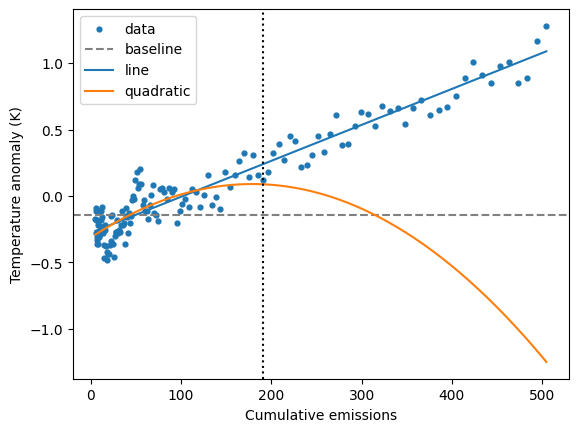

In [ ]:
xs = np.linspace(df["cum_emissions"].min(),
                 df["cum_emissions"].max(), 200)

plt.scatter(df["cum_emissions"], df["temp_anomaly"], s=12, label="data")
plt.axhline(baseline, ls="--", color="gray", label="baseline")
plt.plot(xs, np.polyval(coef1, xs), label="line")
plt.plot(xs, np.polyval(coef2, xs), label="quadratic")
plt.axvline(x_val.max(), ls=":", color="k")   # test starts here
plt.xlabel("Cumulative emissions")
plt.ylabel("Temperature anomaly (K)")
plt.legend()
plt.show()

Text(0.5, 1.0, 'Temperature anomaly vs cumulative emissions')

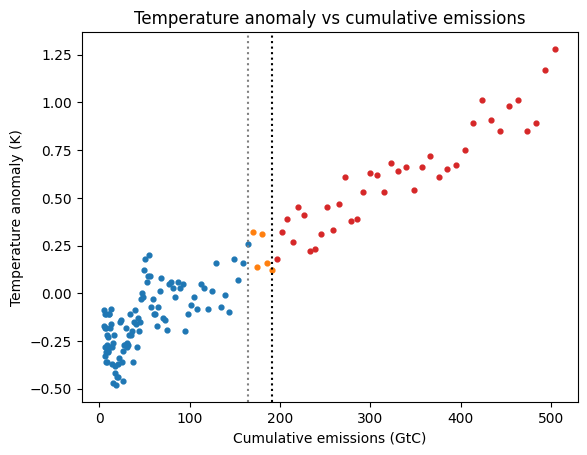

In [ ]:
plt.scatter(x_train, y_train, s=12, color="tab:blue", label="train")
plt.scatter(x_val,   y_val,   s=12, color="tab:orange", label="validation")
plt.scatter(x_test,  y_test,  s=12, color="tab:red", label="test")
plt.axvline(x_train.max(), ls=":", color="gray")
plt.axvline(x_val.max(),   ls=":", color="k")
plt.xlabel("Cumulative emissions (GtC)")
plt.ylabel("Temperature anomaly (K)")
plt.title("Temperature anomaly vs cumulative emissions")

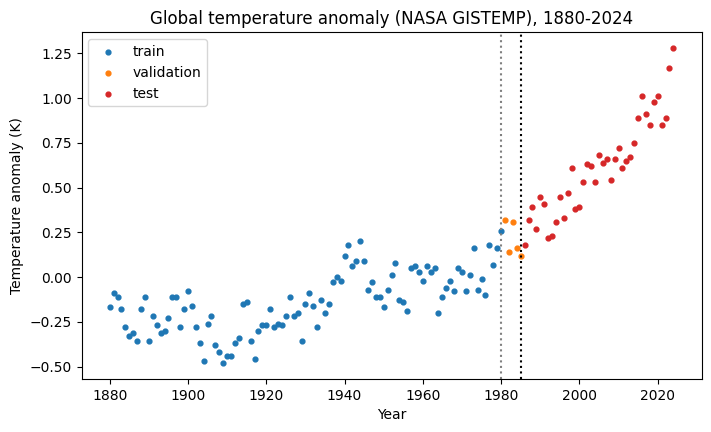

In [ ]:
plt.figure(figsize=(8, 4.5))
plt.scatter(train["year"], train["temp_anomaly"], s=12, color="tab:blue", label="train")
plt.scatter(val["year"],   val["temp_anomaly"],   s=12, color="tab:orange", label="validation")
plt.scatter(test["year"],  test["temp_anomaly"],  s=12, color="tab:red", label="test")

plt.axvline(train["year"].max(), ls=":", color="gray")   # train/validation boundary
plt.axvline(val["year"].max(),   ls=":", color="k")      # start of test period

plt.xlabel("Year")
plt.ylabel("Temperature anomaly (K)")
plt.title("Global temperature anomaly (NASA GISTEMP), 1880-2024")
plt.legend()
plt.show()

In [ ]:
from scipy.optimize import curve_fit

def line(t, a, b):
    return a * t + b

def quad(t, a, b, c):
    return a * t**2 + b * t + c

# years since 1880, for each split
t_train, t_val, t_test = train["year"] - 1880, val["year"] - 1880, test["year"] - 1880

popt1, pcov1 = curve_fit(line, t_train, y_train)
popt2, pcov2 = curve_fit(quad, t_train, y_train)

print("line params:", popt1, "+/-", np.sqrt(np.diag(pcov1)))
print("quad params:", popt2, "+/-", np.sqrt(np.diag(pcov2)))

for name, f, p in [("line", line, popt1), ("quadratic", quad, popt2)]:
    print(f"{name:10s} val RMSE = {rmse(y_val, f(t_val, *p)):.3f}   "
          f"test RMSE = {rmse(y_test, f(t_test, *p)):.3f}")

line params: [ 0.00385079 -0.33313337] +/- [0.00042583 0.02464647]
quad params: [ 4.48610823e-05 -6.35321979e-04 -2.59112586e-01] +/- [1.57772952e-05 1.63047487e-03 3.52785046e-02]
line       val RMSE = 0.172   test RMSE = 0.522
quadratic  val RMSE = 0.111   test RMSE = 0.298


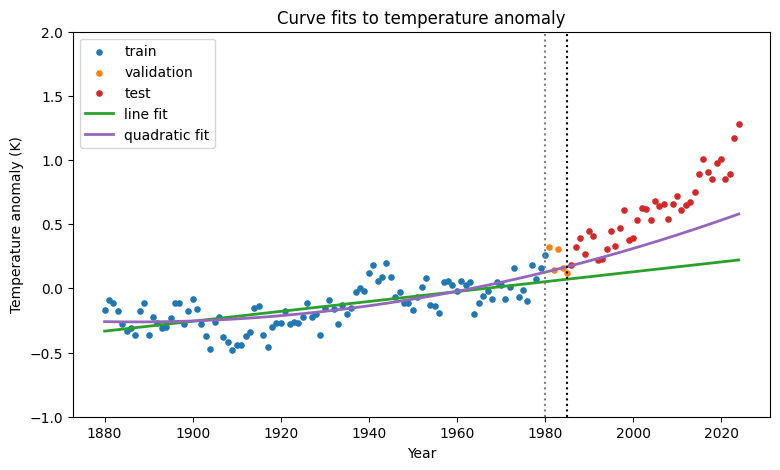

In [ ]:
tt = np.linspace(0, df["year"].max() - 1880, 300)   # years since 1880

plt.figure(figsize=(9, 5))
plt.scatter(train["year"], y_train, s=14, color="tab:blue",   label="train")
plt.scatter(val["year"],   y_val,   s=14, color="tab:orange", label="validation")
plt.scatter(test["year"],  y_test,  s=14, color="tab:red",    label="test")

plt.plot(tt + 1880, line(tt, *popt1), color="tab:green",  lw=2, label="line fit")
plt.plot(tt + 1880, quad(tt, *popt2), color="tab:purple", lw=2, label="quadratic fit")

plt.axvline(train["year"].max(), ls=":", color="gray")
plt.axvline(val["year"].max(),   ls=":", color="k")

plt.ylim(-1, 2)          # keeps the quadratic from squashing the plot
plt.xlabel("Year")
plt.ylabel("Temperature anomaly (K)")
plt.title("Curve fits to temperature anomaly")
plt.legend()
plt.show()